# OASIS INFOBYTE Internship
## Task 2: Unemployment Analysis with Python

**Objective:** To analyse unemployment trends in India using Python, Pandas, Matplotlib and Seaborn.

**Author:** Vasuki S


## 1. Importing Libraries and Loading the Dataset

In this step, we import the required Python libraries for data manipulation, numerical calculations and visualisation. We then load the two CSV files downloaded from Kaggle into Pandas DataFrames for further analysis.

In [1]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Find uploaded CSV files
csv_files = glob.glob("/content/*.csv")

print("CSV files found:")
for file in csv_files:
    print(os.path.basename(file))

if not csv_files:
    raise FileNotFoundError(
        "No CSV files found. Upload both CSV files "
        "using the Files panel in Google Colab."
    )

# Load each dataset
datasets = {}

for file in csv_files:
    df = pd.read_csv(file, skipinitialspace=True)
    df.columns = df.columns.astype(str).str.strip()
    datasets[os.path.basename(file)] = df

print("\nDatasets loaded successfully!")

CSV files found:
Unemployment in India.csv
Unemployment_Rate_upto_11_2020.csv

Datasets loaded successfully!


## 2. Data Cleaning and Preparation

Check missing values and duplicate records, remove duplicate rows where necessary, and prepare the datasets for analysis.

In [3]:
for name, df in datasets.items():
    print(f"\n{name}")
    print("Rows and columns:", df.shape)
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())


Unemployment in India.csv
Rows and columns: (768, 7)
Missing values: 196
Duplicate rows: 27

Unemployment_Rate_upto_11_2020.csv
Rows and columns: (267, 9)
Missing values: 0
Duplicate rows: 0


## 3. Data Cleaning

The first dataset contains missing values and duplicate records. In this step, we remove duplicate rows, handle missing values in numerical columns using their median, and standardise text columns. The second dataset is already complete, so we retain its records while removing any unnecessary whitespace.

In [4]:
for name, df in datasets.items():
    # Remove duplicate records
    df.drop_duplicates(inplace=True)

    # Remove leading and trailing spaces from text columns
    for col in df.select_dtypes(include="object").columns:
        df[col] = df[col].str.strip()

    # Convert percentage and numeric-looking columns where appropriate
    for col in df.columns:
        if col not in df.select_dtypes(include="object").columns:
            continue

        converted = pd.to_numeric(
            df[col].astype(str).str.replace("%", "", regex=False),
            errors="coerce"
        )

        if converted.notna().sum() > 0.8 * df[col].notna().sum():
            df[col] = converted

    # Fill missing numerical values with the median
    for col in df.select_dtypes(include="number").columns:
        df[col] = df[col].fillna(df[col].median())

    # Fill missing categorical values with the mode
    for col in df.select_dtypes(include="object").columns:
        if df[col].isna().any() and not df[col].mode().empty:
            df[col] = df[col].fillna(df[col].mode()[0])

    datasets[name] = df

print("Data cleaning completed.")

for name, df in datasets.items():
    print(
        f"{name}: {df.shape[0]} rows, "
        f"{df.isnull().sum().sum()} missing values remaining"
    )

Data cleaning completed.
Unemployment in India.csv: 741 rows, 0 missing values remaining
Unemployment_Rate_upto_11_2020.csv: 267 rows, 0 missing values remaining


## 4. Exploratory Data Analysis

Exploratory Data Analysis (EDA) helps us understand unemployment patterns and relationships in the data. We first identify the relevant columns in each cleaned dataset before creating visualisations.

In [5]:
for name, df in datasets.items():
    print(f"\n{name}")
    print("Columns:", df.columns.tolist())


Unemployment in India.csv
Columns: ['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']

Unemployment_Rate_upto_11_2020.csv
Columns: ['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']


## 5. Unemployment Rate Distribution

A histogram shows the distribution of unemployment rates in the dataset. It helps us understand which unemployment-rate ranges occur most frequently and whether the values are spread out or concentrated within a particular range.

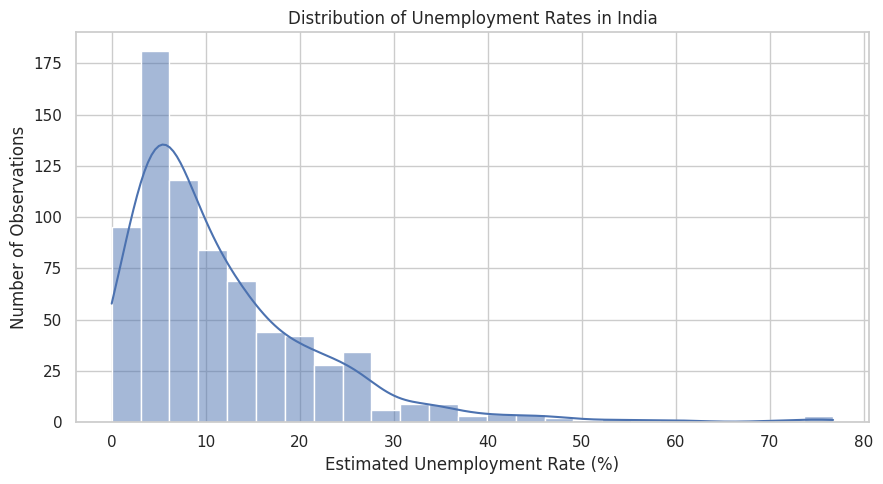

In [6]:
# Select the cleaned dataset
df = datasets["Unemployment in India.csv"]

# Plot the unemployment rate distribution
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df,
    x="Estimated Unemployment Rate (%)",
    bins=25,
    kde=True
)

plt.title("Distribution of Unemployment Rates in India")
plt.xlabel("Estimated Unemployment Rate (%)")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

### Interpretation

The histogram illustrates how frequently different unemployment rates occur in the dataset. The concentration and spread of observations help identify the common unemployment-rate ranges and variations across the recorded observations.

## 6. Monthly Unemployment Trend Analysis

A line chart helps us understand how unemployment rates change over time. We group the observations by month and calculate the average unemployment rate to identify increases, decreases and fluctuations during the study period.

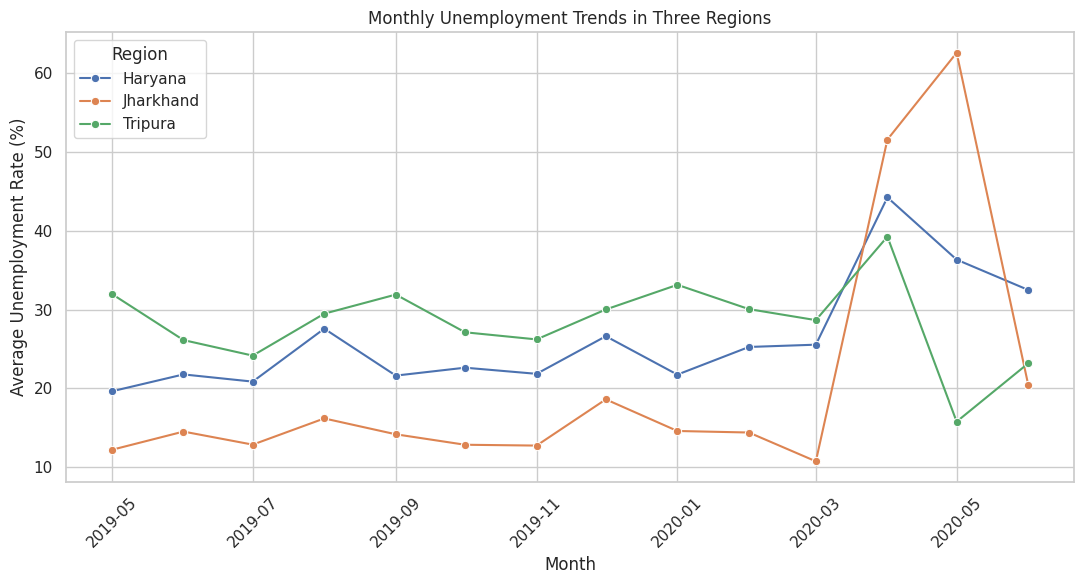

In [15]:
# Prepare dates for time-series analysis
trend_df = datasets["Unemployment in India.csv"].copy()

trend_df["Date"] = pd.to_datetime(
    trend_df["Date"].astype(str).str.strip(),
    dayfirst=True,
    errors="coerce"
)

trend_df = trend_df.dropna(
    subset=["Date", "Estimated Unemployment Rate (%)"]
)

# Select three regions with the highest average unemployment
selected_regions = (
    trend_df.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .nlargest(3)
    .index
)

# Calculate monthly unemployment rates for the selected regions
regional_trend = trend_df[
    trend_df["Region"].isin(selected_regions)
].copy()

regional_trend["Month"] = (
    regional_trend["Date"].dt.to_period("M").dt.to_timestamp()
)

monthly_regional_trend = (
    regional_trend.groupby(["Month", "Region"])
    ["Estimated Unemployment Rate (%)"]
    .mean()
    .reset_index()
)

# Plot the three regional trends
plt.figure(figsize=(11, 6))

sns.lineplot(
    data=monthly_regional_trend,
    x="Month",
    y="Estimated Unemployment Rate (%)",
    hue="Region",
    marker="o"
)

plt.title("Monthly Unemployment Trends in Three Regions")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.legend(title="Region")
plt.tight_layout()
plt.show()

### Interpretation

The line chart compares monthly unemployment rates across three regions selected based on their average unemployment rates in the dataset. The lines show how unemployment fluctuated over time in each region. Differences in the trends highlight regional variation during the period covered by the data.

## 7. State-wise Unemployment Analysis

This analysis compares the average unemployment rates across different regions in India. A bar chart is used to identify the ten regions with the highest average unemployment rates in the dataset.

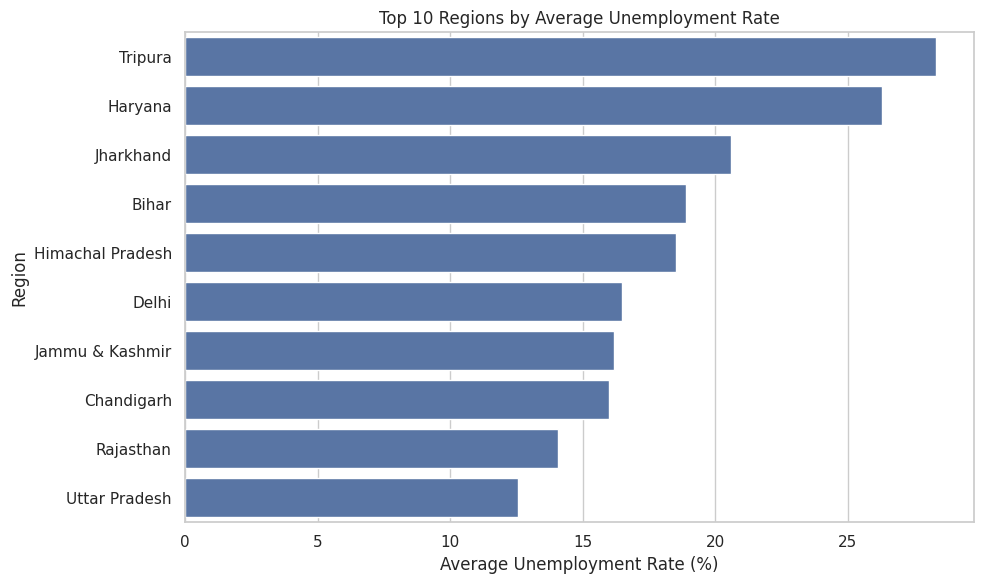

In [8]:
# Calculate average unemployment rate for each region
region_unemployment = (
    df.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

# Plot the top 10 regions
plt.figure(figsize=(10, 6))

sns.barplot(
    data=region_unemployment,
    x="Estimated Unemployment Rate (%)",
    y="Region"
)

plt.title("Top 10 Regions by Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

### Interpretation

The bar chart compares the ten regions with the highest average unemployment rates in the dataset. The longest bars represent regions with higher average rates, helping identify areas that may require further investigation. These averages reflect only the period covered by the dataset.

## 8. Correlation Analysis

Correlation analysis helps identify relationships between numerical variables. A heatmap represents these relationships using colours and correlation coefficients, helping us understand how unemployment, employment and labour-force participation vary together.

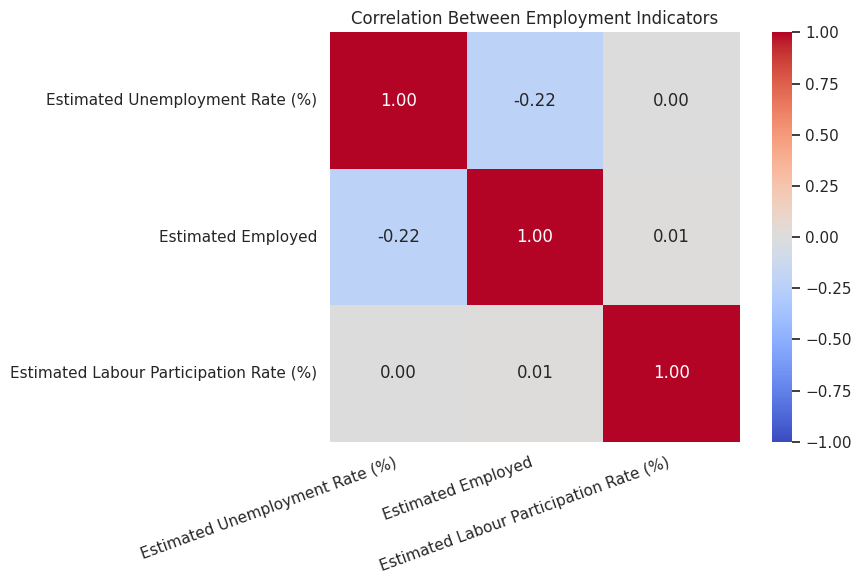

In [16]:
correlation_columns = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

correlation_data = df[correlation_columns].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(
    correlation_data,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlation Between Employment Indicators")
plt.xticks(rotation=20, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretation

The heatmap displays the strength and direction of the linear relationships between unemployment, employment and labour-force participation. Positive values indicate that two variables tend to increase together, while negative values indicate that one tends to decrease as the other increases. Correlation does not establish causation.


## 9. Pre-COVID and Post-COVID Unemployment Comparison

This analysis compares average unemployment rates before and after the onset of the COVID-19 pandemic. March 2020 is used as the cutoff month. The comparison helps identify differences in the recorded unemployment rates across these two periods.

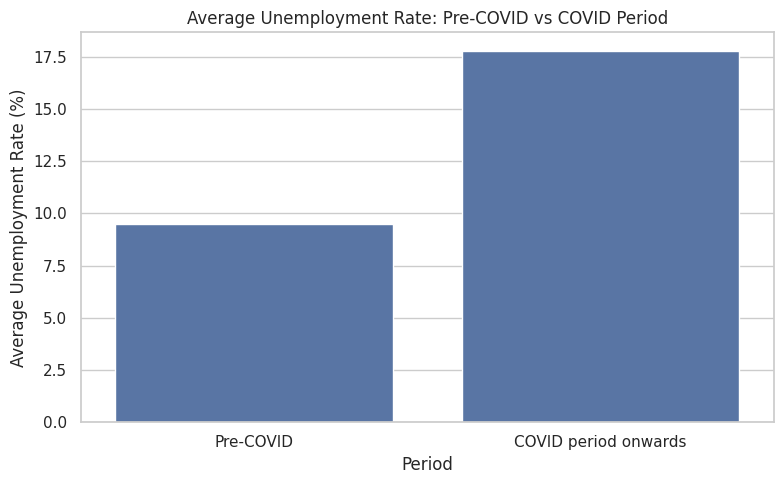

,Period,Estimated Unemployment Rate (%)
0,Pre-COVID,9.51
1,COVID period onwards,17.77


In [20]:
# Compare unemployment rates before and from March 2020 onwards

covid_df = datasets["Unemployment in India.csv"].copy()

# Convert dates from text to datetime format
covid_df["Date"] = pd.to_datetime(
    covid_df["Date"].astype(str).str.strip(),
    dayfirst=True,
    errors="coerce"
)

# Remove rows with invalid dates or missing unemployment rates
covid_df = covid_df.dropna(
    subset=["Date", "Estimated Unemployment Rate (%)"]
)

# Classify observations into two periods
covid_df["Period"] = np.where(
    covid_df["Date"] < pd.Timestamp("2020-03-01"),
    "Pre-COVID",
    "COVID period onwards"
)

# Calculate average unemployment rate for each period
covid_comparison = (
    covid_df.groupby("Period")["Estimated Unemployment Rate (%)"]
    .mean()
    .reindex(["Pre-COVID", "COVID period onwards"])
    .dropna()
    .reset_index()
)

# Plot the comparison
plt.figure(figsize=(8, 5))

sns.barplot(
    data=covid_comparison,
    x="Period",
    y="Estimated Unemployment Rate (%)"
)

plt.title("Average Unemployment Rate: Pre-COVID vs COVID Period")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

display(covid_comparison.round(2))

### Interpretation

The bar chart compares the average unemployment rate before March 2020 with the rate from March 2020 onwards in the available dataset. The difference indicates how the recorded averages varied between these periods. Since the dataset covers only a limited period, this comparison does not establish long-term post-pandemic trends or prove that COVID-19 alone caused the observed changes.

## 10. State-wise Employment Analysis

This analysis compares the estimated number of employed people across regions. A bar chart helps identify regions with higher and lower recorded employment levels in the dataset.

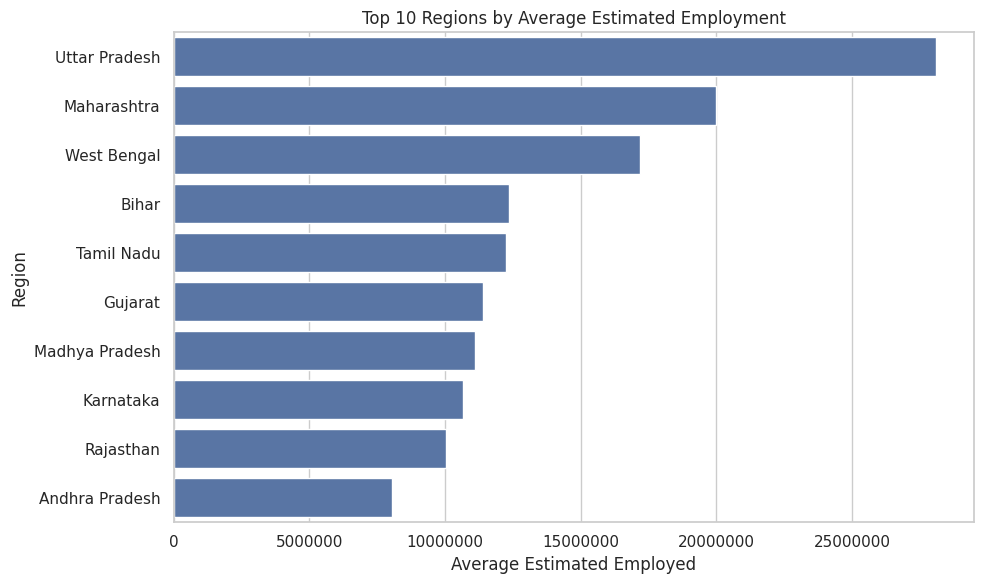

In [17]:
# Calculate average estimated employment by region
region_employment = (
    df.groupby("Region")["Estimated Employed"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=region_employment,
    x="Estimated Employed",
    y="Region"
)

plt.title("Top 10 Regions by Average Estimated Employment")
plt.xlabel("Average Estimated Employed")
plt.ylabel("Region")
plt.ticklabel_format(axis="x", style="plain")
plt.xlim(left=0)
plt.tight_layout()
plt.show()

### Interpretation

The chart compares average estimated employment across the ten regions with the highest recorded employment values. These figures reflect the dataset's estimates and should not be interpreted as direct comparisons of employment rates, because regional population sizes may differ.

## 11. Labour Force Participation Analysis

The estimated labour force participation rate indicates the proportion of the population participating in the labour force, according to the dataset's methodology. This analysis compares the average participation rate across regions.

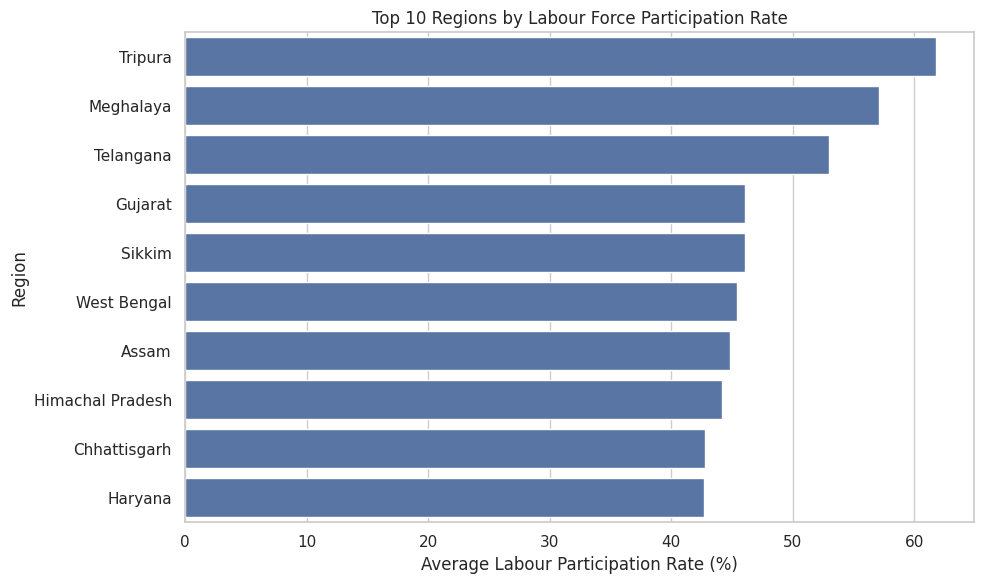

In [12]:
# Calculate average labour force participation by region
region_participation = (
    df.groupby("Region")[
        "Estimated Labour Participation Rate (%)"
    ]
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=region_participation,
    x="Estimated Labour Participation Rate (%)",
    y="Region"
)

plt.title("Top 10 Regions by Labour Force Participation Rate")
plt.xlabel("Average Labour Participation Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

### Interpretation

The chart compares the average labour force participation rates of the ten regions with the highest recorded values. Differences across regions may reflect variations in labour market participation during the period covered by the dataset.

## 12. Key Findings and Observations

This section summarises the main patterns identified through the unemployment analysis, regional comparisons, employment indicators and COVID-period comparison.

In [13]:
print("KEY FINDINGS")
print("-" * 40)

print(
    "Average unemployment rate:",
    round(df["Estimated Unemployment Rate (%)"].mean(), 2), "%"
)

print(
    "Highest average unemployment region:",
    region_unemployment.iloc[0]["Region"],
    "-",
    round(
        region_unemployment.iloc[0]["Estimated Unemployment Rate (%)"],
        2
    ),
    "%"
)

print(
    "Lowest average unemployment region:",
    df.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .idxmin(),
    "-",
    round(
        df.groupby("Region")["Estimated Unemployment Rate (%)"]
        .mean()
        .min(),
        2
    ),
    "%"
)

print(
    "Average estimated employment:",
    f"{df['Estimated Employed'].mean():,.0f}"
)

print(
    "Average labour force participation rate:",
    round(
        df["Estimated Labour Participation Rate (%)"].mean(), 2
    ),
    "%"
)

print(
    "Pre-COVID average unemployment rate:",
    round(covid_comparison.iloc[0, 1], 2), "%"
)

print(
    "COVID-period onwards average unemployment rate:",
    round(covid_comparison.iloc[1, 1], 2), "%"
)

KEY FINDINGS
----------------------------------------
Average unemployment rate: 11.78 %
Highest average unemployment region: Tripura - 28.35 %
Lowest average unemployment region: Meghalaya - 4.8 %
Average estimated employment: 7,201,140
Average labour force participation rate: 42.63 %
Pre-COVID average unemployment rate: 9.51 %
COVID-period onwards average unemployment rate: 17.77 %


## 14. Final Validation

This step verifies that both datasets are available, the cleaned data contains records, and the key numerical columns have no missing values after preprocessing.

In [19]:
# Final Validation

required_columns = [
    "Region",
    "Date",
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

print("FINAL VALIDATION")
print("-" * 40)

for name, data in datasets.items():
    print(f"\nDataset: {name}")
    print("Rows:", len(data))
    print("Missing values:", data.isnull().sum().sum())
    print("Duplicate rows:", data.duplicated().sum())

    missing_columns = [
        col for col in required_columns
        if col not in data.columns
    ]

    if missing_columns:
        print("Missing required columns:", missing_columns)
    else:
        print("Required columns: Available")

    if len(data) == 0:
        print("Status: FAILED - Dataset is empty")
    elif missing_columns:
        print("Status: FAILED - Required columns missing")
    elif data.isnull().sum().sum() > 0:
        print("Status: CHECK - Missing values remain")
    else:
        print("Status: PASSED - Basic checks completed")

# Confirm that both datasets were loaded
expected_files = {
    "Unemployment in India.csv",
    "Unemployment_Rate_upto_11_2020.csv"
}

loaded_files = set(datasets.keys())

print("\nDATASET AVAILABILITY")
print("-" * 40)

if expected_files.issubset(loaded_files):
    print("Both expected datasets are loaded successfully.")
else:
    print("Warning: One or more expected datasets are missing.")

print("\nTask 2 final validation completed.")

FINAL VALIDATION
----------------------------------------

Dataset: Unemployment in India.csv
Rows: 741
Missing values: 0
Duplicate rows: 0
Required columns: Available
Status: PASSED - Basic checks completed

Dataset: Unemployment_Rate_upto_11_2020.csv
Rows: 267
Missing values: 0
Duplicate rows: 0
Required columns: Available
Status: PASSED - Basic checks completed

DATASET AVAILABILITY
----------------------------------------
Both expected datasets are loaded successfully.

Task 2 final validation completed.


## 13. Conclusion

This project analysed unemployment trends in India using Python. Pandas was used for data loading, cleaning and analysis, while Matplotlib and Seaborn were used to create visualisations.

The analysis examined unemployment-rate distributions, monthly trends, regional differences, employment levels, labour force participation and differences between pre-COVID and COVID-period observations.

The results demonstrate how data analysis and visualisation can help identify patterns in labour market indicators. However, the findings are limited to the available dataset and should not be interpreted as proof of causation or as a representation of current unemployment conditions.